<a href="https://colab.research.google.com/github/Abish-Devcraft/DSGP-GRP11-SPATIUM/blob/room-classifier/DSGP_roomclasifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# io wraps raw image bytes in memory so Pillow can open streamed files directly
import io
# os lets us check file paths, extract folder names, and measure file sizes
import os
# tarfile lets us read a .tar archive over an HTTP stream without downloading the whole file
import tarfile
# urllib.request opens a direct streaming connection to MIT's official Places365 server
import urllib.request
# pandas loads your existing manifest CSV and appends the additional Places365 rows
import pandas as pd
# PIL (Pillow) decodes, checks, converts, and saves each streamed room photo
from PIL import Image
# tqdm displays a clean progress bar as we collect the remaining Places365 images
from tqdm import tqdm

# Point to the exact project folders already created in your earlier cells
base_dir = "/content/spatium_room_classifier"
data_dir = os.path.join(base_dir, "data")
extracted_dir = os.path.join(data_dir, "extracted")
manifest_path = os.path.join(data_dir, "extracted_manifest.csv")

# Load the existing manifest (2,571 MIT67 + 2,500 Places365) so we don't repeat work
existing_df = pd.read_csv(manifest_path)
records = existing_df.to_dict("records")

# The 5 residential room classes we want for our classifier
target_rooms = ["bathroom", "bedroom", "dining_room", "kitchen", "living_room"]

# Map raw Places365 folder names to our 5 standard class names
category_map = {
    "bathroom": "bathroom",
    "bedroom": "bedroom",
    "dining_room": "dining_room",
    "kitchen": "kitchen",
    "living_room": "living_room",
}

# New target cap: 1,000 Places365 images per room (5,000 Places365 total)
max_per_room = 1000

# Count how many Places365 images we already saved per room so we continue numbering cleanly
p365_existing = existing_df[existing_df["source_dataset"] == "places365"]
p365_counts = {
    room: int((p365_existing["room_type"] == room).sum())
    for room in target_rooms
}

print("Current Places365 counts before top-up:", p365_counts)

# Official MIT Places365-Standard training archive URL (256x256 images)
train_tar_url = "http://data.csail.mit.edu/places/places365/train_256_places365standard.tar"

# Track how many files per target room we see in the stream so we skip the first 500 already saved
stream_seen_counts = {room: 0 for room in target_rooms}

# Calculate how many new images still need to be downloaded
remaining_needed = sum(max(0, max_per_room - c) for c in p365_counts.values())

if remaining_needed == 0:
    print("All rooms already have 1,000 Places365 images!")
else:
    req = urllib.request.Request(train_tar_url, headers={"User-Agent": "Mozilla/5.0"})
    pbar = tqdm(total=remaining_needed, desc="Topping up Places365 to 1,000/room")

    with urllib.request.urlopen(req, timeout=60) as http_stream:
        with tarfile.open(fileobj=http_stream, mode="r|*") as tar:
            for member in tar:
                # Skip directory entries; we only want image files
                if not member.isfile():
                    continue

                lower_path = member.name.lower()
                if not lower_path.endswith((".jpg", ".jpeg", ".png")):
                    continue

                # Grab the parent folder name (e.g., '.../b/bathroom/00001.jpg' -> 'bathroom')
                folder_name = os.path.basename(os.path.dirname(lower_path))

                # Ignore the other 360 scene categories immediately
                if folder_name not in category_map:
                    continue

                room_type = category_map[folder_name]

                # Skip the first N images of this room that we already extracted earlier
                if stream_seen_counts[room_type] < p365_counts[room_type]:
                    stream_seen_counts[room_type] += 1
                    continue

                # If this room has now reached 1,000 images, check if all 5 rooms are done
                if p365_counts[room_type] >= max_per_room:
                    if all(c >= max_per_room for c in p365_counts.values()):
                        break
                    continue

                # Extract raw image bytes from the stream into RAM
                extracted_file = tar.extractfile(member)
                if extracted_file is None:
                    continue
                raw_bytes = extracted_file.read()

                try:
                    with Image.open(io.BytesIO(raw_bytes)) as img:
                        img.load()
                        orig_mode = img.mode
                        # Standardize grayscale or RGBA images to 3-channel RGB
                        if img.mode != "RGB":
                            img = img.convert("RGB")

                        # Continue sequential ID numbering (e.g., places365_bathroom_0500)
                        idx = p365_counts[room_type]
                        p365_counts[room_type] += 1
                        stream_seen_counts[room_type] += 1
                        pbar.update(1)

                        image_id = f"places365_{room_type}_{idx:04d}"
                        dst_path = os.path.join(extracted_dir, room_type, f"{image_id}.jpg")
                        img.save(dst_path, format="JPEG", quality=95)

                        records.append({
                            "image_id": image_id,
                            "source_dataset": "places365",
                            "room_type": room_type,
                            "filepath": dst_path,
                            "orig_mode": orig_mode,
                            "width": img.width,
                            "height": img.height,
                            "file_size_kb": round(os.path.getsize(dst_path) / 1024, 2),
                        })
                except Exception:
                    # Skip any corrupt/truncated file without interrupting the stream
                    continue

    pbar.close()

# Save the updated 7,571-row combined manifest CSV
combined_df = pd.DataFrame(records)
combined_df.to_csv(manifest_path, index=False)

print("\nTop-up complete! Updated combined dataset breakdown:")
print(pd.crosstab(
    combined_df["room_type"],
    combined_df["source_dataset"],
    margins=True,
    margins_name="Total"
))
print(f"\nUpdated manifest saved at: {manifest_path}")

Current Places365 counts before top-up: {'bathroom': 500, 'bedroom': 500, 'dining_room': 500, 'kitchen': 500, 'living_room': 500}


Topping up Places365 to 1,000/room: 100%|██████████| 2500/2500 [04:58<00:00,  8.36it/s]



Top-up complete! Updated combined dataset breakdown:
source_dataset  mit67  places365  Total
room_type                              
bathroom          203       1000   1203
bedroom           659       1000   1659
dining_room       274       1000   1274
kitchen           733       1000   1733
living_room       702       1000   1702
Total            2571       5000   7571

Updated manifest saved at: /content/spatium_room_classifier/data/extracted_manifest.csv


1. Combined Summary Statistics by Room Category (MIT67 + Places365):
             total_images  mit67_count  places365_count  mean_width  \
room_type                                                             
bathroom             1203          203             1000       283.0   
bedroom              1659          659             1000       319.6   
dining_room          1274          274             1000       290.4   
kitchen              1733          733             1000       323.7   
living_room          1702          702             1000       322.0   

             mean_height  min_width  min_height  mean_size_kb  share_%  
room_type                                                               
bathroom           283.0        256         256          19.9     15.9  
bedroom            319.6        256         256          29.1     21.9  
dining_room        290.4        256         256          29.5     16.8  
kitchen            323.7        256         256          31.0     22

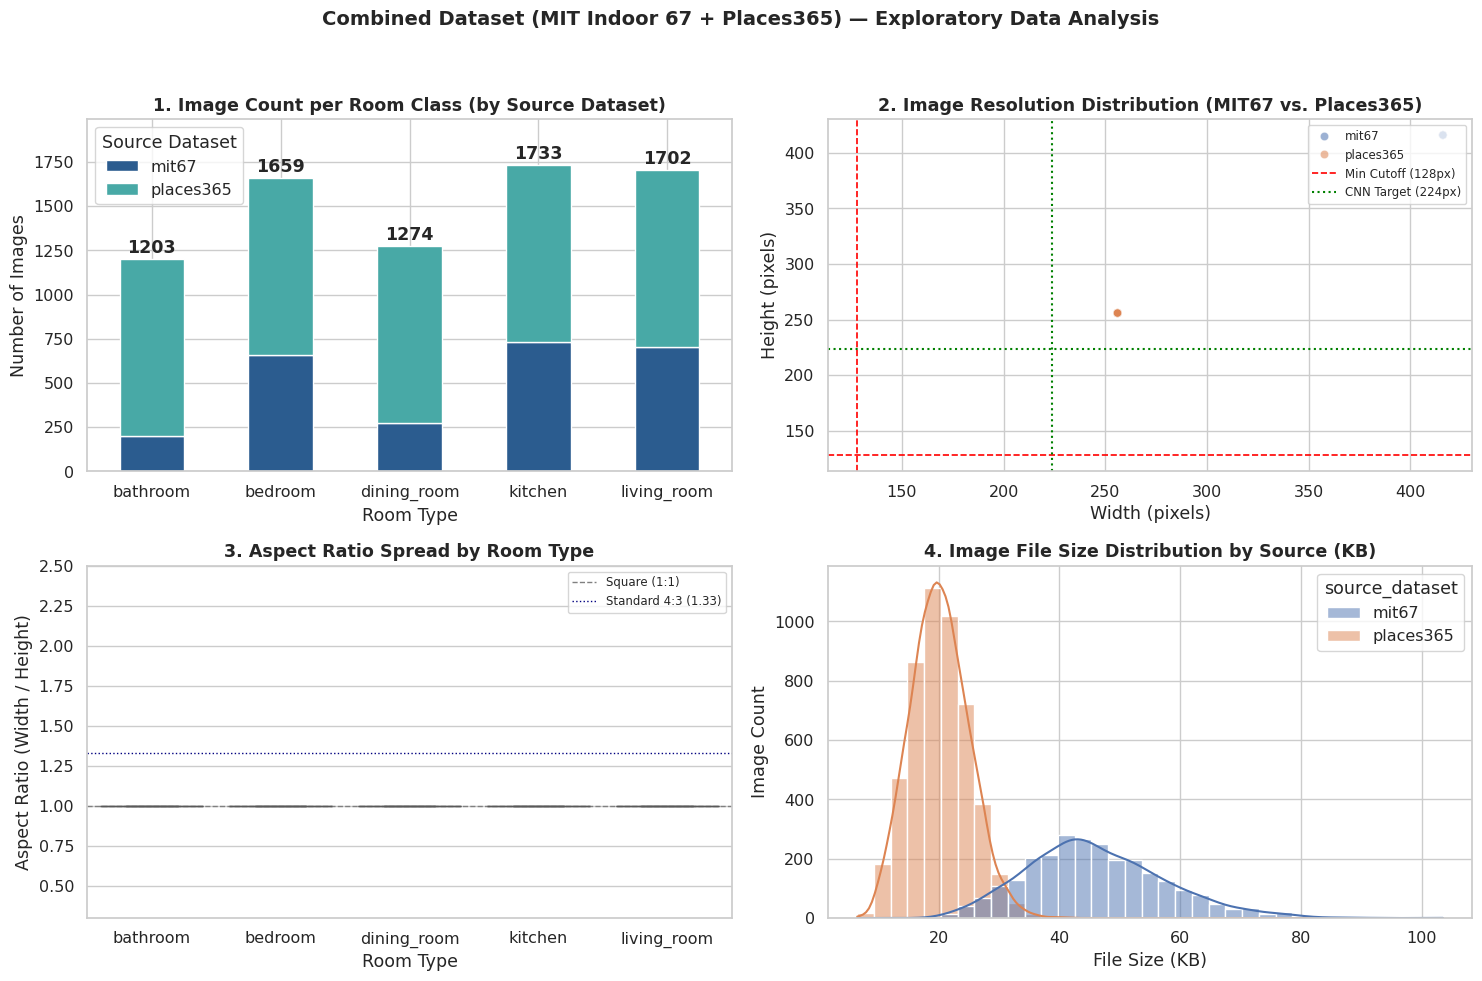

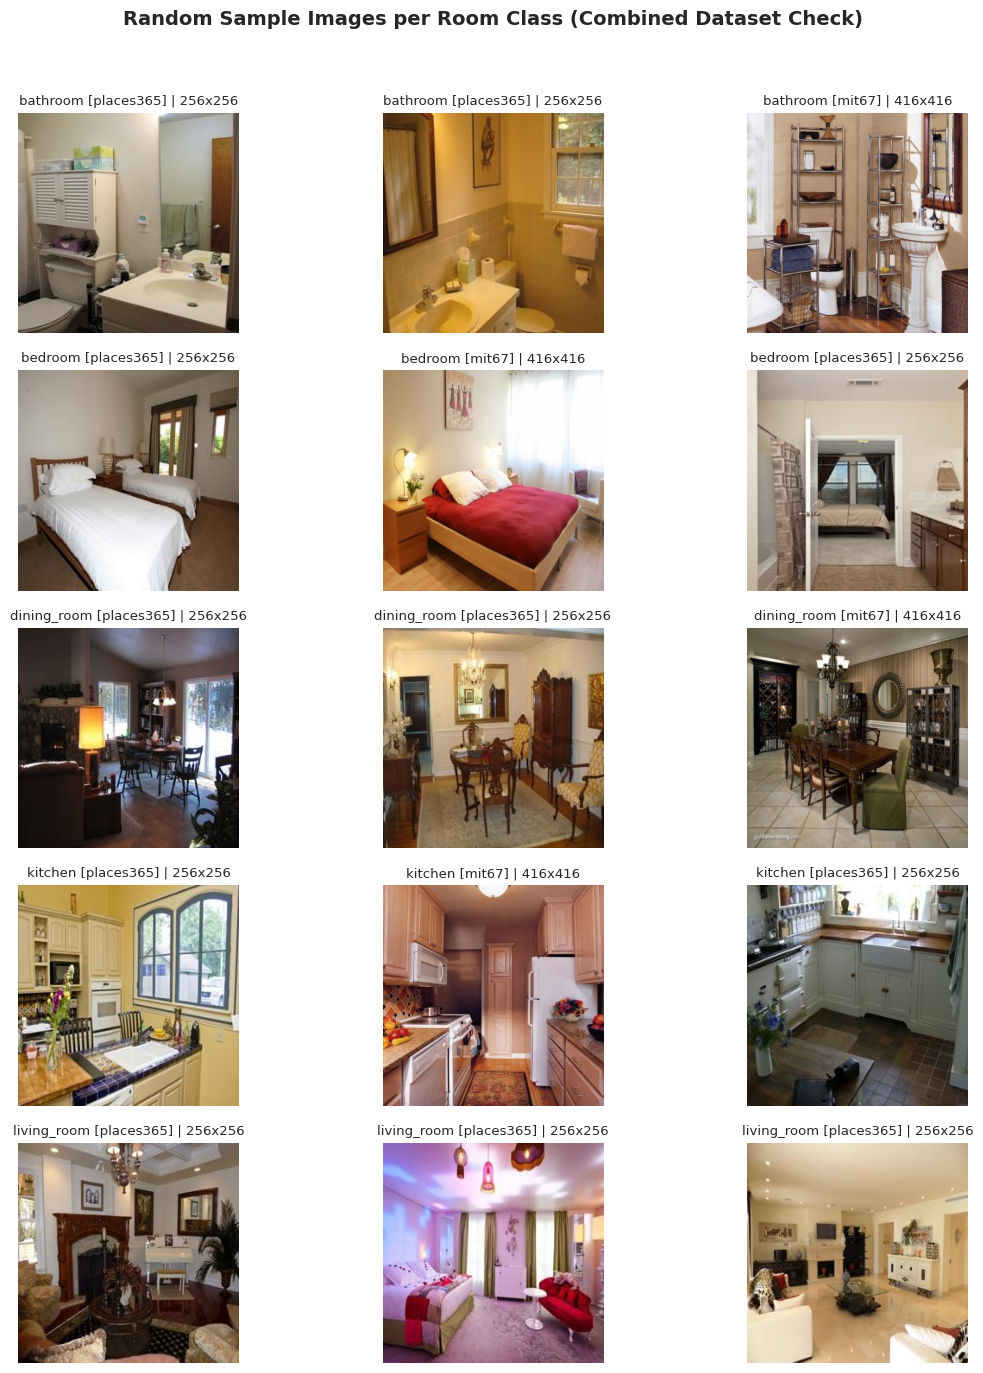


Key Combined EDA Takeaways for Cleaning & Modeling:
- Total combined images: 7571
- Class imbalance ratio (largest vs. smallest class): 1.44x
- Low-resolution images (< 128px on shortest side): 0
- Non-RGB images converted during extraction: 0


In [ ]:
# os lets us build file paths to our saved CSV manifest and images
import os
# pandas loads our combined extracted_manifest.csv so we can run stats on both datasets
import pandas as pd
# matplotlib handles the figure layout, titles, and showing plots
import matplotlib.pyplot as plt
# seaborn sits on top of matplotlib and makes statistical charts look clean
import seaborn as sns
# PIL (Pillow) opens the actual room photos so we can display a sample grid
from PIL import Image

# Set a clean grid background and readable font size for all charts
sns.set_theme(style="whitegrid", font_scale=1.05)

# Point to the project folder and the combined manifest CSV created in Step 1
base_dir = "/content/spatium_room_classifier"
manifest_path = os.path.join(base_dir, "data/extracted_manifest.csv")

# Load the combined MIT67 + Places365 metadata table into a pandas DataFrame
df = pd.read_csv(manifest_path)

# Calculate the aspect ratio (width divided by height) for every image
df["aspect_ratio"] = (df["width"] / df["height"]).round(3)
# Find the shorter edge of each image so we can spot tiny/low-res photos easily
df["min_side"] = df[["width", "height"]].min(axis=1)

# --- Part 1: Print Combined Summary Statistics Tables ---
print("1. Combined Summary Statistics by Room Category (MIT67 + Places365):")
summary_stats = df.groupby("room_type").agg(
    total_images=("image_id", "count"),
    mit67_count=("source_dataset", lambda s: (s == "mit67").sum()),
    places365_count=("source_dataset", lambda s: (s == "places365").sum()),
    mean_width=("width", "mean"),
    mean_height=("height", "mean"),
    min_width=("width", "min"),
    min_height=("height", "min"),
    mean_size_kb=("file_size_kb", "mean"),
).round(1)
# Add a percentage column so we can clearly see overall class balance
summary_stats["share_%"] = ((summary_stats["total_images"] / len(df)) * 100).round(1)
print(summary_stats)

print("\n2. Source Dataset Comparison (MIT67 vs. Places365):")
source_stats = df.groupby("source_dataset").agg(
    image_count=("image_id", "count"),
    mean_width=("width", "mean"),
    mean_height=("height", "mean"),
    mean_size_kb=("file_size_kb", "mean"),
).round(1)
print(source_stats)

# --- Part 2: Build a 2x2 Grid of EDA Charts ---
# Sort room names alphabetically so every chart uses the exact same x-axis order
room_order = sorted(df["room_type"].unique())

# Create a 2-row by 2-column canvas for our four graphs
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
# Add an overall title reflecting the combined dataset
fig.suptitle("Combined Dataset (MIT Indoor 67 + Places365) — Exploratory Data Analysis", fontsize=14, fontweight="bold")

# Chart 1 (Top-Left): Stacked bar chart showing MIT67 vs. Places365 contribution per room
ax1 = axes[0, 0]
ct = pd.crosstab(df["room_type"], df["source_dataset"]).reindex(room_order)
ct.plot(
    kind="bar",
    stacked=True,
    color=["#2B5C8F", "#48A9A6"],
    ax=ax1,
    rot=0
)
ax1.set_title("1. Image Count per Room Class (by Source Dataset)", fontweight="bold")
ax1.set_xlabel("Room Type")
ax1.set_ylabel("Number of Images")
ax1.legend(title="Source Dataset")
# Give the y-axis 15% extra headroom so the total labels above the bars don't clip
ax1.set_ylim(0, ct.sum(axis=1).max() * 1.15)
# Print the combined total on top of each stacked bar
for idx, total in enumerate(ct.sum(axis=1)):
    ax1.text(idx, total + (ct.sum(axis=1).max() * 0.02), str(total), ha="center", fontweight="bold")

# Chart 2 (Top-Right): Scatter plot of Width vs. Height to check image resolutions
ax2 = axes[0, 1]
sns.scatterplot(
    data=df,
    x="width",
    y="height",
    hue="source_dataset",
    alpha=0.55,
    ax=ax2
)
# Draw red dashed lines at 128px (our minimum size cutoff before we drop low-res images)
ax2.axvline(128, color="red", linestyle="--", linewidth=1.2, label="Min Cutoff (128px)")
ax2.axhline(128, color="red", linestyle="--", linewidth=1.2)
# Draw green dotted lines at 224px (the standard input size our CNN will expect)
ax2.axvline(224, color="green", linestyle=":", linewidth=1.5, label="CNN Target (224px)")
ax2.axhline(224, color="green", linestyle=":", linewidth=1.5)
ax2.set_title("2. Image Resolution Distribution (MIT67 vs. Places365)", fontweight="bold")
ax2.set_xlabel("Width (pixels)")
ax2.set_ylabel("Height (pixels)")
ax2.legend(fontsize=8.5, loc="upper right")

# Chart 3 (Bottom-Left): Boxplot of Aspect Ratios to see how stretched or square photos are
ax3 = axes[1, 0]
sns.boxplot(
    data=df,
    x="room_type",
    y="aspect_ratio",
    hue="room_type",
    order=room_order,
    palette="Set2",
    legend=False,
    ax=ax3
)
# Reference line at 1.0 (perfectly square) and 1.33 (standard 4:3 camera photo)
ax3.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="Square (1:1)")
ax3.axhline(1.33, color="navy", linestyle=":", linewidth=1, label="Standard 4:3 (1.33)")
ax3.set_title("3. Aspect Ratio Spread by Room Type", fontweight="bold")
ax3.set_xlabel("Room Type")
ax3.set_ylabel("Aspect Ratio (Width / Height)")
ax3.set_ylim(0.3, 2.5)
ax3.legend(fontsize=8.5)

# Chart 4 (Bottom-Right): Overlapping histogram of file sizes (KB) for both datasets
ax4 = axes[1, 1]
sns.histplot(
    data=df,
    x="file_size_kb",
    hue="source_dataset",
    bins=35,
    kde=True,
    ax=ax4
)
ax4.set_title("4. Image File Size Distribution by Source (KB)", fontweight="bold")
ax4.set_xlabel("File Size (KB)")
ax4.set_ylabel("Image Count")

# Adjust spacing between subplots so titles and axis labels never overlap
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# --- Part 3: Visual Sample Grid (3 Random Images per Room Class) ---
# Create a 5-row (one per room) by 3-column grid to visually inspect real examples
fig, axes = plt.subplots(len(room_order), 3, figsize=(12, 14))
fig.suptitle("Random Sample Images per Room Class (Combined Dataset Check)", fontsize=14, fontweight="bold")

# Loop through each room class (rows)
for row_idx, room in enumerate(room_order):
    # Filter the DataFrame to just the current room and pick 3 random rows
    samples = df[df["room_type"] == room].sample(3, random_state=42)
    # Loop through the 3 sampled images (columns)
    for col_idx, (_, sample_row) in enumerate(samples.iterrows()):
        ax = axes[row_idx, col_idx]
        # Open the image file and display it in the grid slot
        with Image.open(sample_row["filepath"]) as img:
            ax.imshow(img)
        # Show the room label, source dataset, pixel size, and original color mode
        ax.set_title(
            f"{room} [{sample_row['source_dataset']}] | {sample_row['width']}x{sample_row['height']}",
            fontsize=9.5
        )
        # Hide pixel tick marks around the photo borders
        ax.axis("off")

# Tighten the layout and display the sample image grid
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# --- Part 4: Quick Data Quality Check Preview ---
# Count how many images fall below 128px or were originally grayscale/RGBA
low_res_count = (df["min_side"] < 128).sum()
non_rgb_count = (df["orig_mode"] != "RGB").sum()
imbalance_ratio = round(summary_stats["total_images"].max() / summary_stats["total_images"].min(), 2)

print("\nKey Combined EDA Takeaways for Cleaning & Modeling:")
print(f"- Total combined images: {len(df)}")
print(f"- Class imbalance ratio (largest vs. smallest class): {imbalance_ratio}x")
print(f"- Low-resolution images (< 128px on shortest side): {low_res_count}")
print(f"- Non-RGB images converted during extraction: {non_rgb_count}")

Scanning combined dataset (MIT67 + Places365) for corrupt files, low-res, and duplicates...


Cleaning Combined Dataset: 100%|██████████| 7571/7571 [00:46<00:00, 163.22it/s]



================ COMBINED DATA CLEANING REPORT ================
total_checked             : 7571
removed_null_or_corrupt   : 0
removed_low_resolution    : 0
removed_duplicates        : 40
kept_clean                : 7531

Final Clean Image Breakdown (MIT67 vs. Places365):
source_dataset  mit67  places365  Total
room_type                              
bathroom          197        999   1196
bedroom           645       1000   1645
dining_room       274        999   1273
kitchen           728        999   1727
living_room       693        997   1690
Total            2537       4994   7531


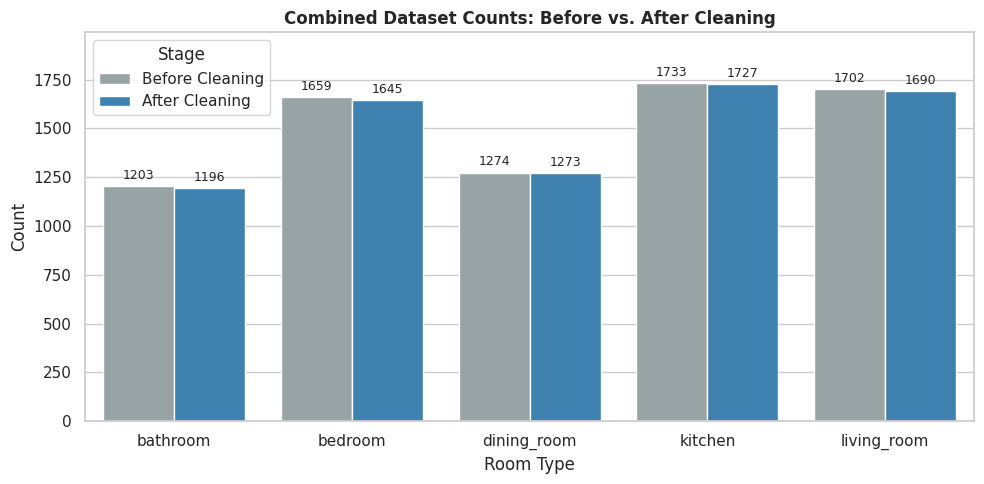

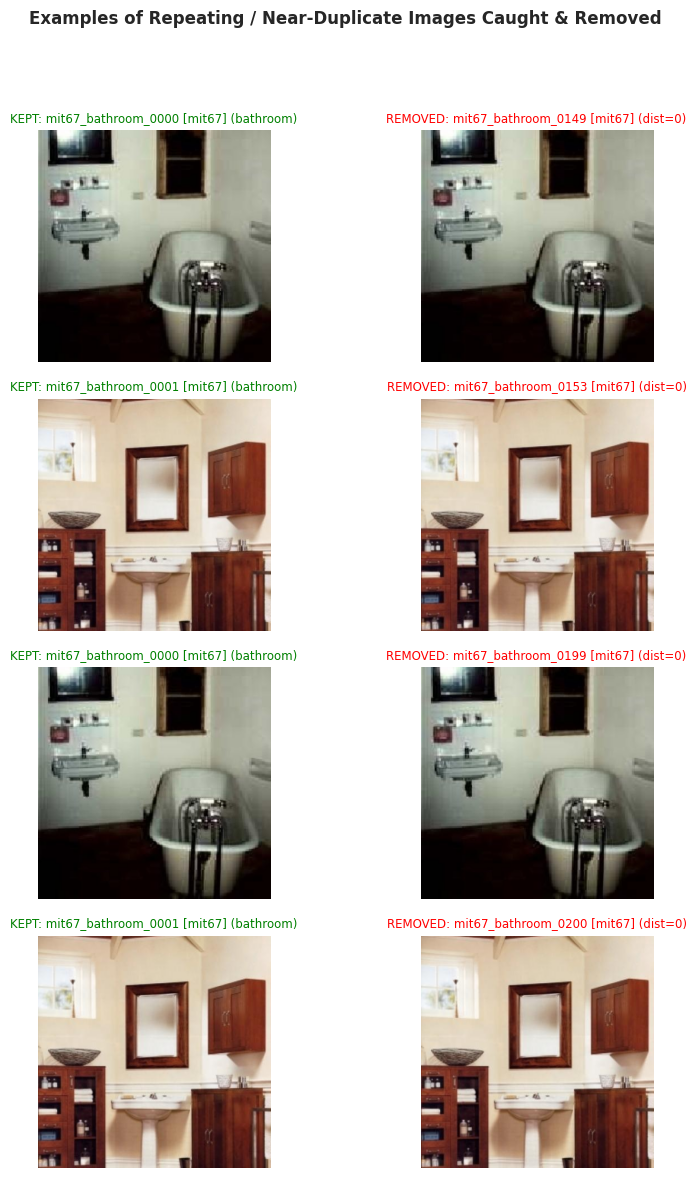

In [ ]:
# Install ImageHash quietly so we can detect exact and near-duplicate images
!pip install -q ImageHash

# os lets us check file sizes, join paths, and create the cleaned folders
import os
# shutil lets us wipe old folders cleanly if we re-run this cleaning cell
import shutil
# numpy speeds up perceptual hash comparisons across 7,500+ combined images
import numpy as np
# pandas reads our combined extracted manifest CSV and saves cleaned_manifest.csv
import pandas as pd
# PIL (Pillow) opens each image and forces full pixel decoding to catch broken files
from PIL import Image
# imagehash creates a visual "fingerprint" (perceptual hash) for each photo
import imagehash
# tqdm shows a progress bar while we scan through all the room folders
from tqdm import tqdm
# matplotlib and seaborn let us plot a before-vs-after chart and show duplicate examples
import matplotlib.pyplot as plt
import seaborn as sns

# Set up our folder paths based on where Step 1 saved the combined extracted images
base_dir = "/content/spatium_room_classifier"
data_dir = os.path.join(base_dir, "data")
extracted_manifest_path = os.path.join(data_dir, "extracted_manifest.csv")
cleaned_dir = os.path.join(data_dir, "cleaned")
cleaned_manifest_path = os.path.join(data_dir, "cleaned_manifest.csv")

# If we ran this cell earlier, delete the old cleaned folder so we start completely fresh
if os.path.exists(cleaned_dir):
    shutil.rmtree(cleaned_dir)

# Quality thresholds:
# Drop images smaller than 128px on either side since upscaling tiny thumbnails blurs room details
min_dimension = 128
# Two photos with a perceptual hash difference <= 5 bits are treated as repeating/near-duplicates
hash_threshold = 5

# Load the combined metadata table (MIT67 + Places365) created during Step 1
raw_df = pd.read_csv(extracted_manifest_path)

# Sort deterministically so the exact same original image is always kept first
raw_df = raw_df.sort_values(by=["room_type", "source_dataset", "image_id"]).reset_index(drop=True)

# Get the sorted list of our 5 room classes and create clean output subfolders for each
target_rooms = sorted(raw_df["room_type"].unique())
for room in target_rooms:
    os.makedirs(os.path.join(cleaned_dir, room), exist_ok=True)

# Counters to keep track of every single image we inspect or drop across both datasets
audit_stats = {
    "total_checked": 0,
    "removed_null_or_corrupt": 0,
    "removed_low_resolution": 0,
    "removed_duplicates": 0,
    "kept_clean": 0,
}

# Store accepted 64-bit boolean hash arrays and their metadata for fast vectorized matching
accepted_hash_arrays = []
accepted_meta = []

# List to store pairs of repeating images so we can inspect/plot them afterward
duplicate_examples = []
# List to store metadata rows for the final verified clean images
cleaned_records = []
# Separate file numbering counter per room class
clean_counters = {room: 0 for room in target_rooms}

print("Scanning combined dataset (MIT67 + Places365) for corrupt files, low-res, and duplicates...")

# Loop through every row in the combined extracted dataset
for _, row in tqdm(raw_df.iterrows(), total=len(raw_df), desc="Cleaning Combined Dataset"):
    audit_stats["total_checked"] += 1
    src_path = row["filepath"]
    room = row["room_type"]
    img_id = row["image_id"]
    source_ds = row["source_dataset"]

    # Check 1: Catch missing or 0-byte (null/empty) files on disk
    if not os.path.exists(src_path) or os.path.getsize(src_path) == 0:
        audit_stats["removed_null_or_corrupt"] += 1
        continue

    try:
        # Open the image and call load() to force Pillow to decode every pixel
        # (This catches truncated or corrupted JPEGs that just opening the header would miss)
        with Image.open(src_path) as img:
            img.load()
            w, h = img.size

            # Check 2: Reject images that are too small (< 128px width or height)
            if w < min_dimension or h < min_dimension:
                audit_stats["removed_low_resolution"] += 1
                continue

            # Make sure the image is strictly 3-channel RGB
            if img.mode != "RGB":
                img = img.convert("RGB")

            # Check 3: Compute a 64-bit perceptual hash to detect repeating/near-duplicate photos
            # .hash.flatten() gives a 64-element boolean array we can compare rapidly via NumPy
            curr_hash_arr = imagehash.phash(img).hash.flatten()

            if len(accepted_hash_arrays) > 0:
                # Stack accepted hashes into a 2D matrix and compute Hamming distances all at once
                hash_matrix = np.asarray(accepted_hash_arrays)
                distances = np.count_nonzero(hash_matrix != curr_hash_arr, axis=1)
                min_idx = int(np.argmin(distances))
                min_dist = int(distances[min_idx])

                # If a match within <= 5 bits is found (within or across MIT67/Places365), drop it
                if min_dist <= hash_threshold:
                    prev_id, prev_room, prev_source, prev_path = accepted_meta[min_idx]
                    audit_stats["removed_duplicates"] += 1
                    duplicate_examples.append({
                        "kept_id": prev_id,
                        "kept_room": prev_room,
                        "kept_source": prev_source,
                        "kept_path": prev_path,
                        "dropped_id": img_id,
                        "dropped_room": room,
                        "dropped_source": source_ds,
                        "dropped_path": src_path,
                        "distance": min_dist,
                    })
                    continue

            # If the image passed all checks, register its hash so future duplicates get caught
            accepted_hash_arrays.append(curr_hash_arr)
            accepted_meta.append((img_id, room, source_ds, src_path))

            # Build a gap-free clean filename (e.g., bedroom_0000.jpg)
            clean_idx = clean_counters[room]
            clean_counters[room] += 1
            clean_id = f"{room}_{clean_idx:04d}"
            dst_path = os.path.join(cleaned_dir, room, f"{clean_id}.jpg")

            # Save the verified image into the cleaned dataset directory
            img.save(dst_path, format="JPEG", quality=95)
            audit_stats["kept_clean"] += 1

            # Record the clean image's details (preserving source_dataset) for our final manifest
            cleaned_records.append({
                "image_id": clean_id,
                "original_id": img_id,
                "source_dataset": source_ds,
                "room_type": room,
                "filepath": dst_path,
                "width": w,
                "height": h,
                "aspect_ratio": round(w / h, 3),
                "file_size_kb": round(os.path.getsize(dst_path) / 1024, 2),
            })

    except Exception:
        # Any image that throws a decoding error gets counted as corrupt and skipped
        audit_stats["removed_null_or_corrupt"] += 1
        continue

# Save the clean combined dataset table to CSV
cleaned_df = pd.DataFrame(cleaned_records)
cleaned_df.to_csv(cleaned_manifest_path, index=False)

# --- Print the Data Cleaning Summary Report ---
print("\n================ COMBINED DATA CLEANING REPORT ================")
for label, value in audit_stats.items():
    print(f"{label:<26}: {value}")
print("===============================================================")

print("\nFinal Clean Image Breakdown (MIT67 vs. Places365):")
print(pd.crosstab(
    cleaned_df["room_type"],
    cleaned_df["source_dataset"],
    margins=True,
    margins_name="Total"
))

# --- Chart 1: Before vs. After Cleaning Comparison ---
sns.set_theme(style="whitegrid")
before_counts = raw_df["room_type"].value_counts().reindex(target_rooms, fill_value=0)
after_counts = cleaned_df["room_type"].value_counts().reindex(target_rooms, fill_value=0)

compare_df = pd.DataFrame({
    "Room Type": target_rooms,
    "Before Cleaning": before_counts.values,
    "After Cleaning": after_counts.values,
}).melt(id_vars="Room Type", var_name="Stage", value_name="Count")

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=compare_df, x="Room Type", y="Count", hue="Stage", palette=["#95A5A6", "#2E86C1"])
ax.set_title("Combined Dataset Counts: Before vs. After Cleaning", fontweight="bold")
ax.set_ylim(0, before_counts.max() * 1.15)
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)
plt.tight_layout()
plt.show()

# --- Chart 2: Visual Proof of Caught Repeating/Duplicate Images ---
if len(duplicate_examples) > 0:
    num_show = min(4, len(duplicate_examples))
    fig, axes = plt.subplots(num_show, 2, figsize=(9, 3 * num_show))
    if num_show == 1:
        axes = [axes]
    fig.suptitle("Examples of Repeating / Near-Duplicate Images Caught & Removed", fontsize=12, fontweight="bold")

    for i in range(num_show):
        pair = duplicate_examples[i]
        with Image.open(pair["kept_path"]) as img_kept, Image.open(pair["dropped_path"]) as img_drop:
            axes[i][0].imshow(img_kept)
            axes[i][0].set_title(
                f"KEPT: {pair['kept_id']} [{pair['kept_source']}] ({pair['kept_room']})",
                fontsize=8.5, color="green"
            )
            axes[i][0].axis("off")

            axes[i][1].imshow(img_drop)
            axes[i][1].set_title(
                f"REMOVED: {pair['dropped_id']} [{pair['dropped_source']}] (dist={pair['distance']})",
                fontsize=8.5, color="red"
            )
            axes[i][1].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()
else:
    print("\nNo repeating/duplicate images found above the similarity threshold.")

Organizing final cleaned images into train, val, and test folders...

================ FINAL CLEANED DATASET SUMMARY ================
Label ID Mapping : {'bathroom': 0, 'bedroom': 1, 'dining_room': 2, 'kitchen': 3, 'living_room': 4}
Total Clean Images: 7531  -->  Train: 5271 | Val: 1130 | Test: 1130

             Total Clean  Train (70%)  Val (15%)  Test (15%)
room_type                                                   
bathroom            1196          837        179         180
bedroom             1645         1151        247         247
dining_room         1273          891        191         191
kitchen             1727         1209        259         259
living_room         1690         1183        254         253
TOTAL               7531         5271       1130        1130

Computed Class Weights (for CrossEntropyLoss during training):
  [0] bathroom     : 1.2595
  [1] bedroom      : 0.9159
  [2] dining_room  : 1.1832
  [3] kitchen      : 0.8720
  [4] living_room  : 0.8911


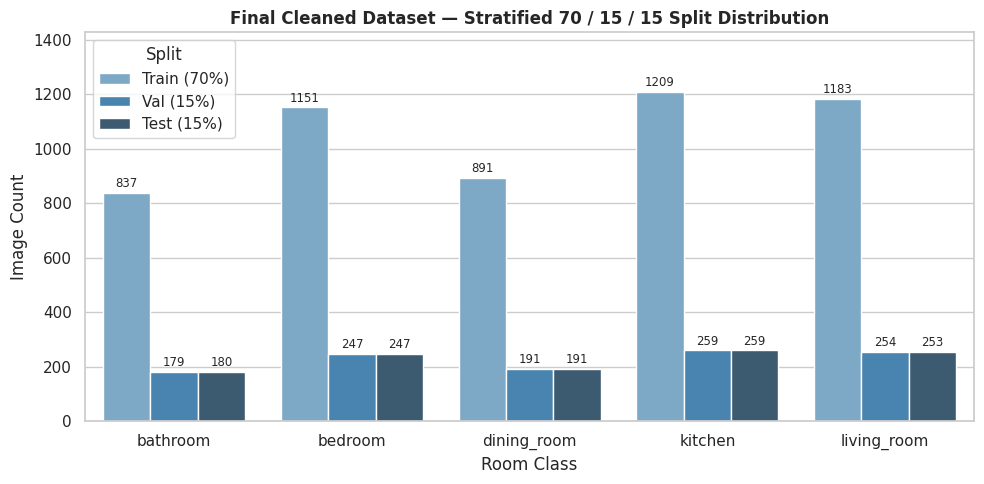

Backing up to Google Drive: 100%|██████████| 22640/22640 [00:08<00:00, 2743.76it/s]


Backup complete! Your final dataset is safely stored in Google Drive at:
/content/drive/MyDrive/SPATIUM_Room_Classifier/data


In [ ]:
# os helps us build folder paths and check if directories already exist
import os
# json lets us save the room-name-to-number mapping in a readable config file
import json
# shutil lets us copy clean images into their final train/val/test folders and Drive
import shutil
# numpy handles numerical arrays when calculating class weights
import numpy as np
# pandas loads cleaned_manifest.csv and saves the final train/val/test CSV tables
import pandas as pd
# torch lets us save the class weights as a PyTorch tensor ready for training
import torch
# train_test_split splits the dataset while keeping exact room ratios across splits
from sklearn.model_selection import train_test_split
# compute_class_weight calculates penalty weights so rare rooms get equal attention
from sklearn.utils.class_weight import compute_class_weight
# matplotlib and seaborn let us plot the final 70/15/15 split breakdown
import matplotlib.pyplot as plt
import seaborn as sns
# tqdm gives us a progress bar while copying files to Google Drive
from tqdm import tqdm

# Set up our main workspace paths from the previous steps
base_dir = "/content/spatium_room_classifier"
data_dir = os.path.join(base_dir, "data")
cleaned_manifest_path = os.path.join(data_dir, "cleaned_manifest.csv")

# Folder where the final physical train/val/test image directories will be created
final_dataset_dir = os.path.join(data_dir, "final_dataset")
# Folder where the split CSV files, label_map.json, and class_weights.pt will live
splits_dir = os.path.join(data_dir, "splits")

# If we ran this cell before, wipe old split/final folders so we start completely clean
for folder in [final_dataset_dir, splits_dir]:
    if os.path.exists(folder):
        shutil.rmtree(folder)
    os.makedirs(folder, exist_ok=True)

# Load the verified clean dataset manifest created in Step 3
df = pd.read_csv(cleaned_manifest_path)

# Sort the 5 room names alphabetically so IDs 0-4 always stay in the exact same order
# (0: bathroom, 1: bedroom, 2: dining_room, 3: kitchen, 4: living_room)
class_names = sorted(df["room_type"].unique().tolist())

# Build dictionaries to convert between text room names and integer IDs (0 to 4)
label_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_label = {idx: name for idx, name in enumerate(class_names)}

# Add a numeric 'label_id' column to the table because neural networks train on numbers
df["label_id"] = df["room_type"].map(label_to_idx)

# Save the label mapping to JSON so our training script and backend use the exact same IDs
label_map_path = os.path.join(splits_dir, "label_map.json")
with open(label_map_path, "w") as f:
    json.dump({"label_to_idx": label_to_idx, "idx_to_label": idx_to_label}, f, indent=2)

# --- Step 4A: Stratified 70% Train / 15% Validation / 15% Test Split ---
# First, separate 70% for training and hold back 30% for validation + testing
# stratify=df["label_id"] guarantees every split keeps the exact same room percentages
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=42
)

# Next, split that 30% holdout pool in half (15% validation, 15% final test)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=42
)

# --- Step 4B: Copy Images into Final Physical Folders (train / val / test) ---
# Put our three split DataFrames in a dictionary so we can process them in one clean loop
splits_dict = {
    "train": train_df.copy(),
    "val": val_df.copy(),
    "test": test_df.copy(),
}

print("Organizing final cleaned images into train, val, and test folders...")

for split_name, split_df in splits_dict.items():
    # Create one subfolder per room class inside final_dataset/<split_name>/
    for room in class_names:
        os.makedirs(os.path.join(final_dataset_dir, split_name, room), exist_ok=True)

    # Keep track of the new file paths so we can update the CSV manifests
    new_paths = []

    # Copy each image from data/cleaned/ into its assigned split folder
    for _, row in split_df.iterrows():
        src_path = row["filepath"]
        room = row["room_type"]
        filename = os.path.basename(src_path)
        dst_path = os.path.join(final_dataset_dir, split_name, room, filename)

        # copy2 preserves original file metadata while copying cleanly
        shutil.copy2(src_path, dst_path)
        new_paths.append(dst_path)

    # Update the filepath column in the split DataFrame to point to the final dataset folder
    split_df["filepath"] = new_paths
    split_df.reset_index(drop=True, inplace=True)

    # Save the split manifest CSV (train.csv, val.csv, test.csv)
    split_csv_path = os.path.join(splits_dir, f"{split_name}.csv")
    split_df.to_csv(split_csv_path, index=False)

# --- Step 4C: Compute Balanced Class Weights (Training Split Only) ---
# Calculate inverse-frequency weights strictly from train_df so val/test info never leaks
weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(class_names)),
    y=splits_dict["train"]["label_id"].values
)

# Convert the NumPy weights into a 32-bit PyTorch float tensor and save it to disk
class_weights_tensor = torch.tensor(weights_array, dtype=torch.float32)
weights_path = os.path.join(splits_dir, "class_weights.pt")
torch.save(class_weights_tensor, weights_path)

# --- Step 4D: Print Final Dataset Summary & Class Weights ---
print("\n================ FINAL CLEANED DATASET SUMMARY ================")
print("Label ID Mapping :", label_to_idx)
print(f"Total Clean Images: {len(df)}  -->  Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}\n")

# Build a clean summary table comparing image counts across every split
summary_table = pd.DataFrame({
    "Total Clean": df["room_type"].value_counts(),
    "Train (70%)": splits_dict["train"]["room_type"].value_counts(),
    "Val (15%)": splits_dict["val"]["room_type"].value_counts(),
    "Test (15%)": splits_dict["test"]["room_type"].value_counts(),
}).reindex(class_names)

# Add a Total row at the bottom of the summary table
summary_table.loc["TOTAL"] = summary_table.sum()
print(summary_table)

print("\nComputed Class Weights (for CrossEntropyLoss during training):")
for idx, room in idx_to_label.items():
    print(f"  [{idx}] {room:<13}: {weights_array[idx]:.4f}")
print("===============================================================")

# --- Step 4E: Plot Final Split Distribution Chart ---
sns.set_theme(style="whitegrid")

# Drop the TOTAL row and Total Clean column so only the 3 split columns are plotted
plot_df = summary_table.drop("TOTAL").drop(columns=["Total Clean"]).copy()
# Name the index explicitly before reset_index() so melt() always finds 'Room Class'
plot_df.index.name = "Room Class"
plot_df = plot_df.reset_index().melt(
    id_vars="Room Class", var_name="Split", value_name="Image Count"
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=plot_df, x="Room Class", y="Image Count", hue="Split", palette="Blues_d")
ax.set_title("Final Cleaned Dataset — Stratified 70 / 15 / 15 Split Distribution", fontweight="bold")
ax.set_ylim(0, splits_dict["train"]["room_type"].value_counts().max() * 1.18)
for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=8.5)
plt.tight_layout()
plt.show()

# --- Step 4F: Back Up Final Dataset to Google Drive ---
# Only mount Google Drive if it isn't already connected in this Colab session
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

drive_backup_dir = "/content/drive/MyDrive/SPATIUM_Room_Classifier/data"

# Count total files first so tqdm can show a live progress bar during the Drive copy
total_files = sum(len(files) for _, _, files in os.walk(data_dir))
pbar = tqdm(total=total_files, desc="Backing up to Google Drive")

# Helper wrapper around copy2 that ticks the progress bar after every copied image
def copy_with_progress(src, dst):
    shutil.copy2(src, dst)
    pbar.update(1)

# Copy the entire data folder to Drive while showing live progress
shutil.copytree(data_dir, drive_backup_dir, copy_function=copy_with_progress, dirs_exist_ok=True)
pbar.close()

print(f"\nBackup complete! Your final dataset is safely stored in Google Drive at:\n{drive_backup_dir}")